In [2]:
from Bio import SeqIO

for seq_record in SeqIO.parse("../data/SRR4163265.fasta", "fasta"):
# for seq_record in SeqIO.parse("../data/oligos.fasta", "fasta"):
    print(seq_record.id)
    print(repr(seq_record))
    print(len(seq_record))
    break

SRR4163265.1
SeqRecord(seq=Seq('GGAGGTACCATAATGGTCGGTAATCCTAACTCTGAAAGTGATAAACACCTTGTT...GAT'), id='SRR4163265.1', name='SRR4163265.1', description='SRR4163265.1 1 length=126', dbxrefs=[])
126


In [1]:
# Load model directly
from transformers import AutoTokenizer, AutoModelForPreTraining

tokenizer = AutoTokenizer.from_pretrained("lhallee/CodonBERT")
model = AutoModelForPreTraining.from_pretrained("lhallee/CodonBERT")

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


To use data.metrics please install scikit-learn. See https://scikit-learn.org/stable/index.html


ImportError: cannot import name 'AutoModelForPreTraining' from 'transformers' (/Users/ailinzhang/Desktop/sequence_optimization_with_CodonBERT/Sequence-Optimization-with-CodonBERT/.pixi/envs/default/lib/python3.13/site-packages/transformers/__init__.py)

In [ ]:
from transformers import AutoTokenizer, AutoModelForPreTraining, AutoModel
import torch
from Bio import SeqIO

# Load CodonBERT
tokenizer = AutoTokenizer.from_pretrained("lhallee/CodonBERT")
model = AutoModelForPreTraining.from_pretrained("lhallee/CodonBERT")

# Get one sequence from fasta
for seq_record in SeqIO.parse("../data/SRR4163265.fasta", "fasta"):
    dna_seq = str(seq_record.seq)
    break

print("Example sequence:", dna_seq[:60], "...")

# Tokenize 
inputs = tokenizer(
    dna_seq,
    return_tensors="pt",
    max_length=512,   # CodonBERT has a context window, truncate if longer
    truncation=True,
    padding="max_length"
)

# Run inference
with torch.no_grad():
    outputs = model(**inputs)

# Masked LM predictions
mlm_logits = outputs.prediction_logits   # [batch_size, seq_len, vocab_size]
print("MLM logits shape:", mlm_logits.shape)

base_model = AutoModel.from_pretrained("lhallee/CodonBERT")

with torch.no_grad():
    emb_outputs = base_model(**inputs)

embeddings = emb_outputs.last_hidden_state  # [batch_size, seq_len, hidden_dim]
print("Embeddings shape:", embeddings.shape)



Example sequence: GGAGGTACCATAATGGTCGGTAATCCTAACTCTGAAAGTGATAAACACCTTGTTACACCG ...
MLM logits shape: torch.Size([1, 512, 69])
Embeddings shape: torch.Size([1, 512, 768])


In [6]:
embeddings

tensor([[[ 0.2680, -0.1236,  0.0787,  ..., -0.1736, -0.9255,  0.1316],
         [ 0.2702, -0.2250,  0.3532,  ...,  0.1391, -1.0764,  0.5688],
         [ 0.5499, -0.4428,  0.3693,  ...,  0.2403, -0.6261,  0.5298],
         ...,
         [ 0.8073, -0.5289,  0.4486,  ...,  0.1888, -0.7543,  0.6473],
         [ 0.9092, -0.5641,  0.2510,  ...,  0.2096, -0.6932,  0.6053],
         [ 0.8399, -0.6432,  0.3131,  ...,  0.3048, -0.6281,  0.6040]]])

test the parquet of SRR

In [6]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent

sys.path.append(str(ROOT / "src"))

from pathlib import Path
from boto3.session import Session
from config import PROFILE_NAME, REGION_NAME

BUCKET = "sequence-data-ztgg"
KEY = "codonbert_inference/embeddings_batch_00001.parquet"
LOCAL_FILE = "embeddings_batch_00001.parquet"

session = Session(profile_name=PROFILE_NAME, region_name=REGION_NAME)
s3 = session.client("s3")

s3.download_file(BUCKET, KEY, LOCAL_FILE)

print("Downloaded:", LOCAL_FILE)

Downloaded: embeddings_batch_00001.parquet


In [7]:
import pandas as pd

df = pd.read_parquet("embeddings_batch_00001.parquet")

print(df.shape)
df.head()

(1000, 771)


,id,clean_seq,num_codons,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,emb_758,emb_759,emb_760,emb_761,emb_762,emb_763,emb_764,emb_765,emb_766,emb_767
0,SRR4163265.1,GGA GGT ACC ATA ATG GTC GGT AAT CCT AAC TCT GA...,42,0.147193,-0.319087,0.243105,-0.270262,0.333919,-0.052783,-0.186103,...,0.021732,0.402986,0.139591,-0.451386,0.048015,-0.146438,0.134187,0.046472,-0.423647,0.629220
1,SRR4163265.1,TCC ACC GGA TCC ACC AGC ACT CGC GAA ACC ACG GA...,42,0.209312,-0.365283,0.215105,-0.119629,0.160537,0.252223,-0.188706,...,0.136594,0.234742,0.269765,-0.588419,0.135941,-0.212176,0.395797,-0.068766,-0.911109,0.378644
2,SRR4163265.2,GGA GGT ACC ATA ATG AGC GTC GGT GTT TGT ATT CC...,42,0.330041,-0.414726,0.446995,0.013615,0.276375,-0.067108,-0.254622,...,0.211351,0.268935,0.354959,-0.483760,0.128693,-0.262377,0.498039,0.063157,-0.551255,0.475222
3,SRR4163265.2,TCC ACC GGA TCC ACC AGT ACC AAC AAT GAT CTG CG...,42,0.114113,-0.227711,0.269597,-0.113284,0.283615,-0.054260,-0.170040,...,0.126437,0.234657,0.388725,-0.386815,0.108719,-0.063981,0.554737,-0.028477,-0.563726,0.352701
4,SRR4163265.3,GGA GGT ACC ATA ATG CAT TCT TTG CAA TTT GGG AC...,42,0.062851,-0.374458,-0.000700,-0.070906,0.336883,0.246255,-0.094347,...,0.068530,0.061557,0.463392,-0.198866,0.129833,-0.570290,0.334498,0.084416,-0.944296,0.244673


In [8]:
emb_cols = [c for c in df.columns if c.startswith("emb_")]

print("embedding columns:", len(emb_cols))
print("NaN count:", df[emb_cols].isna().sum().sum())
print(df[emb_cols].iloc[:, :5].describe())

embedding columns: 768
NaN count: 0
             emb_0        emb_1        emb_2        emb_3        emb_4
count  1000.000000  1000.000000  1000.000000  1000.000000  1000.000000
mean      0.159368    -0.343561     0.244004    -0.129252     0.334230
std       0.111712     0.128839     0.141415     0.118874     0.104064
min      -0.298914    -0.705794    -0.198356    -0.559666     0.051288
25%       0.092948    -0.430038     0.155242    -0.207994     0.263064
50%       0.165802    -0.332923     0.250238    -0.130813     0.333878
75%       0.229772    -0.250355     0.341197    -0.049173     0.406482
max       0.542085     0.025855     0.627776     0.348768     0.667457


Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


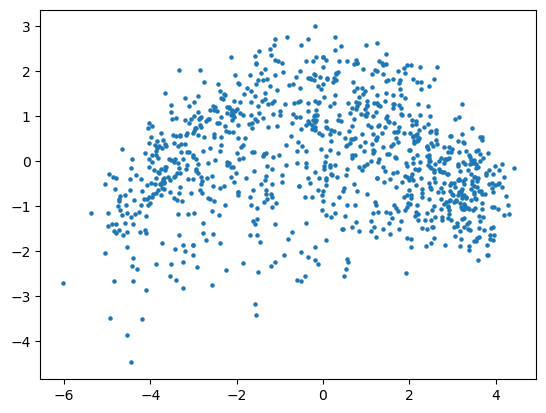

In [ ]:
import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

df = pd.read_parquet("embeddings_batch_00001.parquet")

emb_cols = [c for c in df.columns if c.startswith("emb_")]

X = df[emb_cols].values

pca = PCA(n_components=3)
X_pca = pca.fit_transform(X)

plt.scatter(X_pca[:,0], X_pca[:,1], s=5)
plt.show()